<a href="https://colab.research.google.com/github/malashreekotian9686-ai/ai-agents-for-beginners/blob/main/Diwali_DeepDream_Art.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("Diwali DeepDream project is ready!")


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Diwali DeepDream project is ready!


In [21]:

base_model = tf.keras.applications.InceptionV3(
    include_top=False,
    weights="imagenet"
)

print("DeepDream model loaded successfully!")
print("Total layers:", len(base_model.layers))


DeepDream model loaded successfully!
Total layers: 311


Saving 8db02d83-8a3f-4280-884c-2877d9d22ff1.png to 8db02d83-8a3f-4280-884c-2877d9d22ff1 (1).png


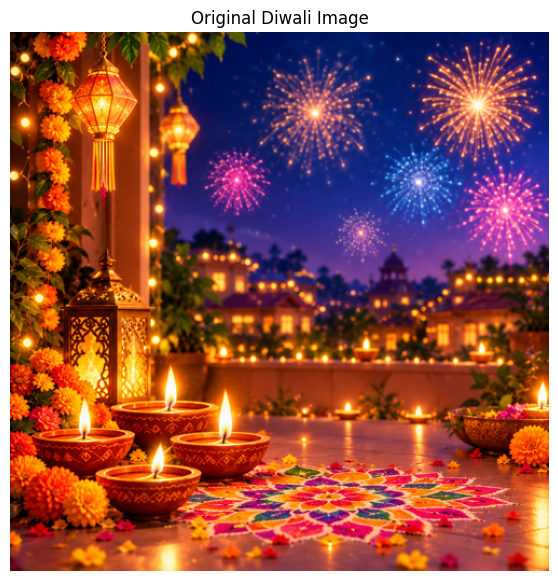

Image uploaded successfully!
Image dimensions: (500, 500, 3)


In [22]:

uploaded = files.upload()

filename = next(iter(uploaded))

img = Image.open(filename).convert("RGB")
img.thumbnail((500, 500))

original_img = np.array(img)

plt.figure(figsize=(7, 7))
plt.imshow(original_img)
plt.title("Original Diwali Image")
plt.axis("off")
plt.show()

print("Image uploaded successfully!")
print("Image dimensions:", original_img.shape)


In [23]:

# Convert the image into a TensorFlow tensor
image_tensor = tf.convert_to_tensor(
    original_img, dtype=tf.float32
)

# Add batch dimension
image_tensor = tf.expand_dims(image_tensor, axis=0)

# Normalize pixels for InceptionV3: 0–255 becomes -1 to 1
dream_image = tf.keras.applications.inception_v3.preprocess_input(
    image_tensor
)

# Select layers that will enhance patterns and textures
layer_names = ["mixed3", "mixed5", "mixed7"]

dream_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[
        base_model.get_layer(name).output
        for name in layer_names
    ]
)

print("Image prepared successfully!")
print("DeepDream layers selected successfully!")
print("Image shape:", dream_image.shape)


Image prepared successfully!
DeepDream layers selected successfully!
Image shape: (1, 500, 500, 3)


In [24]:

def calculate_loss(image):
    activations = dream_model(image)

    losses = [
        tf.reduce_mean(activation)
        for activation in activations
    ]

    return tf.add_n(losses)


def deepdream_step(image, learning_rate=0.01):
    with tf.GradientTape() as tape:
        tape.watch(image)
        loss = calculate_loss(image)

    gradients = tape.gradient(loss, image)

    # Normalize gradients for stable updates
    gradients = gradients / (
        tf.math.reduce_std(gradients) + 1e-8
    )

    image = image + gradients * learning_rate

    # Keep normalized pixel values within the valid range
    image = tf.clip_by_value(image, -1.0, 1.0)

    return image, loss


# Start with the uploaded image
dream_result = tf.identity(dream_image)

# Adjust the number of iterations if needed
steps = 40
learning_rate = 0.01

for step in range(steps):
    dream_result, loss = deepdream_step(
        dream_result, learning_rate
    )

    if (step + 1) % 10 == 0:
        print(
            f"Step {step + 1}/{steps} completed"
            f" | Loss: {loss.numpy():.4f}"
        )

print("DeepDream generation completed!")


Step 10/40 completed | Loss: 1.2186
Step 20/40 completed | Loss: 1.4917
Step 30/40 completed | Loss: 1.6684
Step 40/40 completed | Loss: 1.8023
DeepDream generation completed!


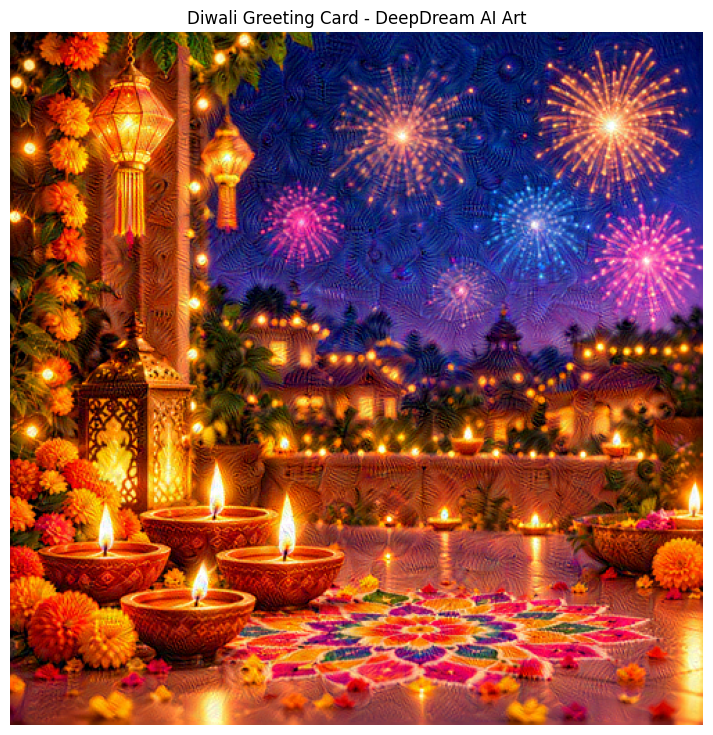

In [25]:

# Convert normalized image values back to RGB pixels
dream_display = dream_result[0].numpy()

dream_display = (dream_display + 1.0) * 127.5
dream_display = np.clip(
    dream_display, 0, 255
).astype(np.uint8)

plt.figure(figsize=(9, 9))
plt.imshow(dream_display)
plt.title("Diwali Greeting Card - DeepDream AI Art")
plt.axis("off")
plt.show()


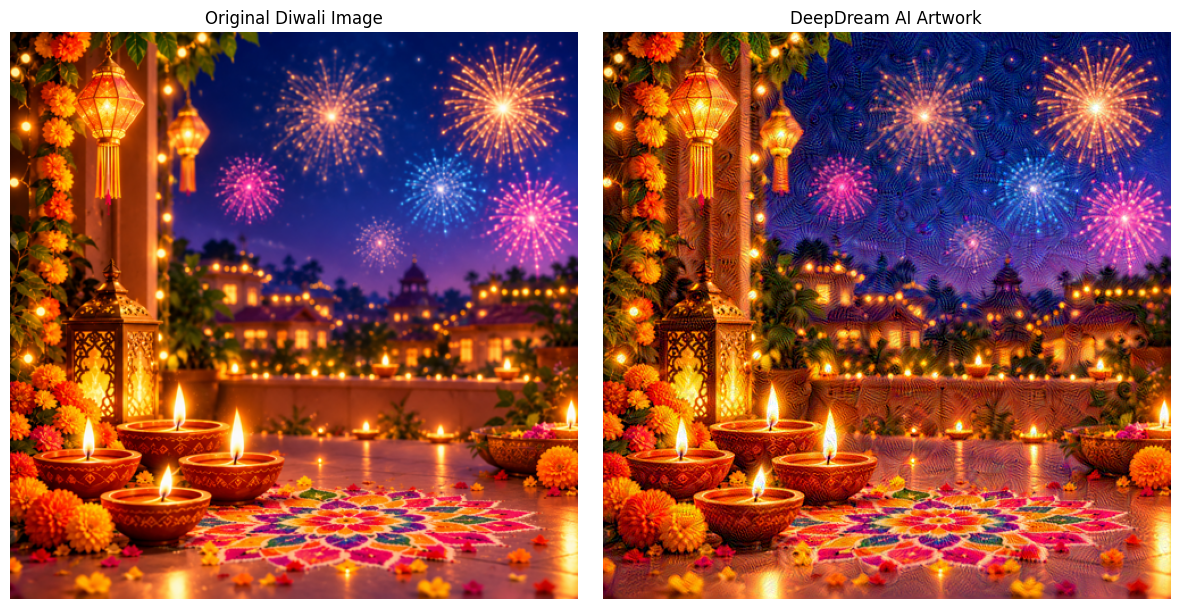

In [26]:

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_img)
plt.title("Original Diwali Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dream_display)
plt.title("DeepDream AI Artwork")
plt.axis("off")

plt.tight_layout()
plt.show()


In [27]:

output_filename = "Diwali_DeepDream_Art.png"

Image.fromarray(dream_display).save(output_filename)

print("Artwork saved successfully!")

files.download(output_filename)


Artwork saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>